<a href="https://colab.research.google.com/github/asheta66/Applications/blob/main/ViT_Potato_Leaf_Classification_128_ver1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Balanced Potato Leaf Classification — Compact Vision Transformer
128×128 RGB images; classes: Early_blight, Healthy, Late_blight.

**Run all cells in Google Colab.** Data: `MyDrive/Potato/<class>/`.

Changes: verify images and remove exact pixel duplicates; stratified 70/15/15 split **before** balancing; randomly undersample only training to the smallest class; fresh online leaf augmentation; smaller ViT, dropout, AdamW, label smoothing, validation macro-F1 checkpointing and early stopping; correct three-class softmax and metrics. Source images are never deleted. Validation/test preserve the available class distribution and are never augmented.

With 1,000/152/1,000 unique valid images, training should contain approximately **106 images per class (318 total)**. Strict undersampling trades majority-class diversity for equal training exposure. It does not guarantee less overfitting: only about 106 distinct Healthy training leaves remain. Healthy validation/test supports are about 23 each, so their estimates are uncertain. Related images of the same leaf/plant require a plant-level split if IDs are available; exact deduplication cannot detect all related images. This remains a from-scratch educational baseline; compare with transfer learning in a separate validation-only experiment.

## 1. Imports and reproducibility

In [3]:
import os, json, hashlib, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix, classification_report,
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers as L

RANDOM_STATE = 42
keras.utils.set_random_seed(RANDOM_STATE)
try:
    tf.config.experimental.enable_op_determinism()
except (AttributeError, RuntimeError) as exc:
    print('Deterministic operations unavailable:', exc)
# Float32 default for numerical stability and portability on this small dataset.
keras.mixed_precision.set_global_policy('float32')
print('TensorFlow:', tf.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Mount Drive, validate images and remove exact duplicates

In [4]:
from google.colab import drive
drive.mount('/content/mydrive')
IMAGE_SIZE = 128
BATCH_SIZE = 16
CLASS_NAMES = ['Early_blight', 'Healthy', 'Late_blight']
N_CLASSES = len(CLASS_NAMES)
DRIVE_DATA_DIR = Path('/content/mydrive/MyDrive/Potato')
OUTPUT_DIR = Path('/content/mydrive/MyDrive/Potato_ViT_Results_Balanced')
FIGURE_DIR = OUTPUT_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
SUPPORTED_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

def save_figure(fig, filename):
    path = FIGURE_DIR / filename
    fig.savefig(path, dpi=220, bbox_inches='tight')
    print('Saved:', path)
    return path

def load_rgb(path):
    with Image.open(path) as im:
        return ImageOps.exif_transpose(im).convert('RGB')

rows, invalid = [], []
for label, name in enumerate(CLASS_NAMES):
    folder = DRIVE_DATA_DIR / name
    if not folder.is_dir():
        raise FileNotFoundError(f'Missing class folder: {folder}')
    paths = sorted(p for p in folder.rglob('*')
                   if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS)
    for p in paths:
        try:
            im = load_rgb(p)
            # Hash decoded RGB pixels + dimensions, independent of filename.
            digest = hashlib.sha256(str(im.size).encode() + im.tobytes()).hexdigest()
            rows.append(dict(image_path=str(p), label=label, class_name=name, content_hash=digest))
        except (OSError, ValueError) as exc:
            invalid.append(dict(image_path=str(p), error=str(exc)))
raw_df = pd.DataFrame(rows)
if raw_df.empty:
    raise ValueError('No readable images found.')
conflicts = raw_df.groupby('content_hash')['label'].nunique()
if (conflicts > 1).any():
    raw_df[raw_df.content_hash.isin(conflicts[conflicts > 1].index)].to_csv(
        OUTPUT_DIR / 'conflicting_labels.csv', index=False)
    raise ValueError('Identical images have conflicting class labels. Fix conflicting_labels.csv first.')
duplicates = raw_df[raw_df.duplicated('content_hash', keep='first')]
duplicates.to_csv(OUTPUT_DIR / 'excluded_duplicates.csv', index=False)
pd.DataFrame(invalid, columns=['image_path', 'error']).to_csv(OUTPUT_DIR / 'invalid_images.csv', index=False)
df = raw_df.drop_duplicates('content_hash').reset_index(drop=True)
counts = df.groupby('class_name').size().reindex(CLASS_NAMES, fill_value=0)
if counts.min() < 10:
    raise ValueError('Need at least 10 unique readable images per class for this split.')
dataset_summary_df = pd.DataFrame({'Class': CLASS_NAMES, 'Count': counts.to_numpy()})
dataset_summary_df['Percent'] = 100 * dataset_summary_df.Count / len(df)
display(dataset_summary_df.round(2))
print(f'Unique valid images: {len(df):,}; invalid: {len(invalid)}; duplicates excluded: {len(duplicates)}')
df.to_csv(OUTPUT_DIR / 'dataset_manifest.csv', index=False)

Mounted at /content/mydrive


,Class,Count,Percent
0,Early_blight,1000,46.47
1,Healthy,152,7.06
2,Late_blight,1000,46.47


Unique valid images: 2,152; invalid: 0; duplicates excluded: 0


## 3. Split first, then balance only training
`TRAIN_MAX_PER_CLASS=None` uses the smallest training class. Set a lower positive integer only to reduce all classes further. No class weights or duplicate oversampling are applied to this already balanced training set.

,Split,Total,Early_blight,Healthy,Late_blight
0,Train pool,1506,700,106,700
1,Train balanced,318,106,106,106
2,Validation,323,150,23,150
3,Test,323,150,23,150


Saved: /content/mydrive/MyDrive/Potato_ViT_Results_Balanced/figures/01_class_balance.png


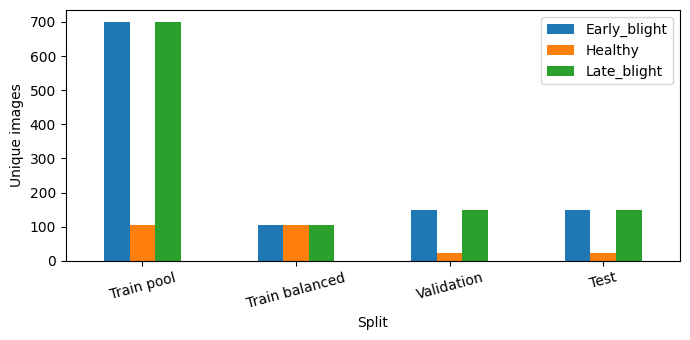

In [5]:
TRAIN_MAX_PER_CLASS = None
train_pool, temp = train_test_split(df, test_size=0.30, stratify=df.label, random_state=RANDOM_STATE)
df_valid, df_test = train_test_split(temp, test_size=0.50, stratify=temp.label, random_state=RANDOM_STATE)
train_pool = train_pool.reset_index(drop=True)
df_valid, df_test = df_valid.reset_index(drop=True), df_test.reset_index(drop=True)
target_per_class = int(train_pool.groupby('label').size().min())
if TRAIN_MAX_PER_CLASS is not None:
    if not isinstance(TRAIN_MAX_PER_CLASS, int) or TRAIN_MAX_PER_CLASS < 1:
        raise ValueError('TRAIN_MAX_PER_CLASS must be a positive integer or None.')
    target_per_class = min(target_per_class, TRAIN_MAX_PER_CLASS)
df_train = pd.concat([
    train_pool[train_pool.label == c].sample(n=target_per_class, random_state=RANDOM_STATE+c)
    for c in range(N_CLASSES)
]).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
excluded_train = train_pool[~train_pool.image_path.isin(df_train.image_path)]
frames = {'Train pool': train_pool, 'Train balanced': df_train, 'Validation': df_valid, 'Test': df_test}
split_summary_df = pd.DataFrame([
    {'Split': name, 'Total': len(frame), **{c:int((frame.class_name == c).sum()) for c in CLASS_NAMES}}
    for name, frame in frames.items()])
display(split_summary_df)
assert df_train.groupby('label').size().nunique() == 1
for a,b in [(train_pool,df_valid),(train_pool,df_test),(df_valid,df_test)]:
    assert set(a.content_hash).isdisjoint(b.content_hash), 'Data leakage detected'
for name, frame in [('train_pool',train_pool),('train_balanced',df_train),
                    ('validation',df_valid),('test',df_test),('excluded_training',excluded_train)]:
    frame.to_csv(OUTPUT_DIR / f'{name}_split.csv', index=False)
split_summary_df.to_csv(OUTPUT_DIR / 'split_summary.csv', index=False)
fig, ax = plt.subplots(figsize=(7,3.5))
split_summary_df.set_index('Split')[CLASS_NAMES].plot.bar(ax=ax)
ax.set_ylabel('Unique images'); ax.tick_params(axis='x', rotation=15)
fig.tight_layout(); save_figure(fig,'01_class_balance.png'); plt.show(); plt.close(fig)

## 4. Efficient datasets and training-only leaf augmentation
Images are cached in RAM after resizing; set `CACHE_DATA=False` if memory is limited. Augmentation runs inside the model only during training, so cached images receive new transforms each epoch. PIL supports every listed extension including TIFF and applies EXIF orientation consistently.

Saved: /content/mydrive/MyDrive/Potato_ViT_Results_Balanced/figures/02_augmented_leaves.png


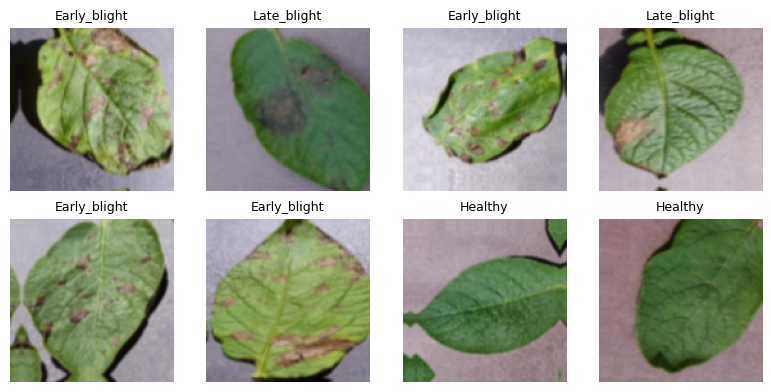

In [6]:
CACHE_DATA = True
AUTOTUNE = tf.data.AUTOTUNE

def read_resized_image(path):
    filename = path.numpy().decode('utf-8')
    im = load_rgb(filename).resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR)
    return np.asarray(im, dtype=np.float32) / 255.0

def decode_record(path, label):
    image = tf.py_function(read_resized_image, [path], Tout=tf.float32)
    image.set_shape((IMAGE_SIZE, IMAGE_SIZE, 3))
    return image, tf.one_hot(label, N_CLASSES)

def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((frame.image_path.to_numpy(), frame.label.to_numpy(dtype=np.int32)))
    ds = ds.map(decode_record, num_parallel_calls=AUTOTUNE, deterministic=True)
    if CACHE_DATA:
        ds = ds.cache()
    if training:
        ds = ds.shuffle(len(frame), seed=RANDOM_STATE, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(df_train, training=True)
train_eval_ds = make_dataset(df_train)
valid_ds = make_dataset(df_valid)
test_ds = make_dataset(df_test)
augmentation = keras.Sequential([
    L.RandomFlip('horizontal_and_vertical', seed=RANDOM_STATE),
    L.RandomRotation(0.15, fill_mode='reflect', seed=RANDOM_STATE+1),
    L.RandomTranslation(0.08, 0.08, fill_mode='reflect', seed=RANDOM_STATE+2),
    L.RandomZoom(0.12, fill_mode='reflect', seed=RANDOM_STATE+3),
    L.RandomContrast(0.10, seed=RANDOM_STATE+4),
], name='leaf_augmentation')
images, labels = next(iter(train_eval_ds))
augmented = tf.clip_by_value(augmentation(images, training=True), 0, 1).numpy()
fig, axes = plt.subplots(2,4,figsize=(8,4))
for i,ax in enumerate(axes.ravel()):
    ax.axis('off')
    if i < len(augmented):
        ax.imshow(augmented[i]); ax.set_title(CLASS_NAMES[int(tf.argmax(labels[i]))], fontsize=9)
fig.tight_layout(); save_figure(fig,'02_augmented_leaves.png'); plt.show(); plt.close(fig)

## 5. Small, serializable ViT with regularization

In [7]:
PATCH_SIZE = 16
PROJECTION_DIM = 32
NUM_HEADS = 4
TRANSFORMER_LAYERS = 2
MLP_HEAD_UNITS = [64]
DROPOUT = 0.25
HEAD_DROPOUT = 0.40
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.05
EPOCHS = 80
PATIENCE = 12
assert IMAGE_SIZE % PATCH_SIZE == 0 and PROJECTION_DIM % NUM_HEADS == 0
NUM_PATCHES = (IMAGE_SIZE // PATCH_SIZE)**2

@keras.utils.register_keras_serializable(package='PotatoViT')
class Patches(L.Layer):
    def __init__(self, patch_size, **kwargs):
        super().__init__(**kwargs); self.patch_size = patch_size
    def call(self, images):
        patches = tf.image.extract_patches(images, sizes=[1,self.patch_size,self.patch_size,1],
            strides=[1,self.patch_size,self.patch_size,1], rates=[1,1,1,1], padding='VALID')
        return tf.reshape(patches, [tf.shape(images)[0], -1, self.patch_size*self.patch_size*3])
    def get_config(self):
        return {**super().get_config(), 'patch_size':self.patch_size}

@keras.utils.register_keras_serializable(package='PotatoViT')
class PatchEncoder(L.Layer):
    def __init__(self, num_patches, projection_dim, **kwargs):
        super().__init__(**kwargs)
        self.num_patches, self.projection_dim = num_patches, projection_dim
        self.projection = L.Dense(projection_dim)
        self.position_embedding = L.Embedding(num_patches, projection_dim)
    def call(self, patches):
        return self.projection(patches) + self.position_embedding(tf.range(self.num_patches))
    def get_config(self):
        return {**super().get_config(), 'num_patches':self.num_patches, 'projection_dim':self.projection_dim}

def mlp(x, units, dropout):
    for u in units:
        x = L.Dense(u, activation='gelu')(x)
        x = L.Dropout(dropout)(x)
    return x

def build_vit():
    inputs = L.Input((IMAGE_SIZE, IMAGE_SIZE, 3))
    x = augmentation(inputs)
    x = L.Rescaling(2.0, offset=-1.0)(x)
    x = PatchEncoder(NUM_PATCHES, PROJECTION_DIM)(Patches(PATCH_SIZE)(x))
    for _ in range(TRANSFORMER_LAYERS):
        y = L.LayerNormalization(epsilon=1e-6)(x)
        y = L.MultiHeadAttention(NUM_HEADS, PROJECTION_DIM//NUM_HEADS, dropout=DROPOUT)(y,y)
        x = L.Add()([x,y])
        y = L.LayerNormalization(epsilon=1e-6)(x)
        y = mlp(y, [PROJECTION_DIM*2, PROJECTION_DIM], DROPOUT)
        x = L.Add()([x,y])
    x = L.GlobalAveragePooling1D()(L.LayerNormalization(epsilon=1e-6)(x))
    x = L.Dropout(HEAD_DROPOUT)(x)
    x = mlp(x, MLP_HEAD_UNITS, HEAD_DROPOUT)
    outputs = L.Dense(N_CLASSES, activation='softmax', dtype='float32', name='class_probabilities')(x)
    return keras.Model(inputs, outputs, name='Compact_Potato_ViT')

model = build_vit()
model.compile(optimizer=keras.optimizers.AdamW(learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY, clipnorm=1.0),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING),
    metrics=[keras.metrics.CategoricalAccuracy(name='accuracy')])
model.summary()

Model: "Compact_Potato_ViT"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaf_augmentation   │ (None, 128, 128,  │          0 │ input_layer_1[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 128, 128,  │          0 │ leaf_augmentatio… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patches (Patches)   │ (None, None, 768) │          0 │ rescaling[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_encoder       │ (None, 64, 32)    │     26,656 │ patches[0][0]     │
│ (PatchEncoder)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 64, 32)    │         64 │ patch_encoder[0]… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 32)    │      4,224 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 32)    │          0 │ patch_encoder[0]… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 32)    │         64 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64, 64)    │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64, 64)    │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64, 32)    │      2,080 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64, 32)    │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 64, 32)    │          0 │ add[0][0],        │
│                     │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 32)    │         64 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 32)    │      4,224 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 64, 32)    │          0 │ add_1[0][0],      │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 32)    │         64 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 46,115 (180.14 KB)

 Trainable params: 46,115 (180.14 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Select the checkpoint with validation macro-F1
Macro-F1 treats all classes equally. Validation loss controls learning-rate reduction. Test images are not accessed during model selection. Callbacks appear in this order so the computed F1 is available to checkpointing, early stopping and CSV logging.

In [8]:
class ValidationMacroF1(keras.callbacks.Callback):
    def __init__(self, dataset, labels):
        super().__init__(); self.dataset = dataset; self.labels = np.asarray(labels)
    def on_epoch_end(self, epoch, logs=None):
        if logs is None:
            logs = {}
        probabilities = self.model.predict(self.dataset, verbose=0)
        predicted = probabilities.argmax(axis=1)
        logs['val_macro_f1'] = f1_score(self.labels, predicted, labels=np.arange(N_CLASSES), average='macro', zero_division=0)
        logs['val_balanced_accuracy'] = balanced_accuracy_score(self.labels, predicted)
        print(f" — val_macro_f1: {logs['val_macro_f1']:.4f}")

best_model_path = OUTPUT_DIR / 'best_vit_potato.keras'
callbacks = [
    ValidationMacroF1(valid_ds, df_valid.label),
    keras.callbacks.ModelCheckpoint(str(best_model_path), monitor='val_macro_f1', mode='max', save_best_only=True),
    keras.callbacks.EarlyStopping(monitor='val_macro_f1', mode='max', patience=PATIENCE, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),
    keras.callbacks.TerminateOnNaN(),
    keras.callbacks.CSVLogger(str(OUTPUT_DIR / 'training_log.csv')),
]
history = model.fit(train_ds, validation_data=valid_ds, epochs=EPOCHS, callbacks=callbacks)
history_df = pd.DataFrame(history.history)
history_df.index.name = 'epoch_zero_based'
history_df.to_csv(OUTPUT_DIR / 'training_history.csv')
model = keras.models.load_model(best_model_path, compile=False)
config = dict(seed=RANDOM_STATE, classes=CLASS_NAMES, image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, target_per_class=target_per_class, split='70/15/15 before undersampling',
    patch_size=PATCH_SIZE, projection_dim=PROJECTION_DIM, transformer_layers=TRANSFORMER_LAYERS,
    learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY, label_smoothing=LABEL_SMOOTHING,
    dropout=DROPOUT, head_dropout=HEAD_DROPOUT, tensorflow_version=tf.__version__)
(OUTPUT_DIR / 'run_config.json').write_text(json.dumps(config, indent=2))

Epoch 1/80
19/20 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.4258 - loss: 1.0993 — val_macro_f1: 0.6483
20/20 ━━━━━━━━━━━━━━━━━━━━ 16s 245ms/step - accuracy: 0.4906 - loss: 1.0412 - val_accuracy: 0.7802 - val_loss: 0.8135 - val_macro_f1: 0.6483 - val_balanced_accuracy: 0.6336 - learning_rate: 3.0000e-04
Epoch 2/80
19/20 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.5638 - loss: 0.9294 — val_macro_f1: 0.6211
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - accuracy: 0.5440 - loss: 0.9612 - val_accuracy: 0.6966 - val_loss: 0.8090 - val_macro_f1: 0.6211 - val_balanced_accuracy: 0.7209 - learning_rate: 3.0000e-04
Epoch 3/80
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.6200 - loss: 0.8880 — val_macro_f1: 0.6973
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.6195 - loss: 0.8982 - val_accuracy: 0.7740 - val_loss: 0.7207 - val_macro_f1: 0.6973 - val_balanced_accuracy: 0.7764 - learning_rate: 3.0000e-04
Epoch 4/80
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.6336 - loss:

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'patch_encoder', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


428

## 7. Learning curves

Saved: /content/mydrive/MyDrive/Potato_ViT_Results_Balanced/figures/03_learning_curves.png


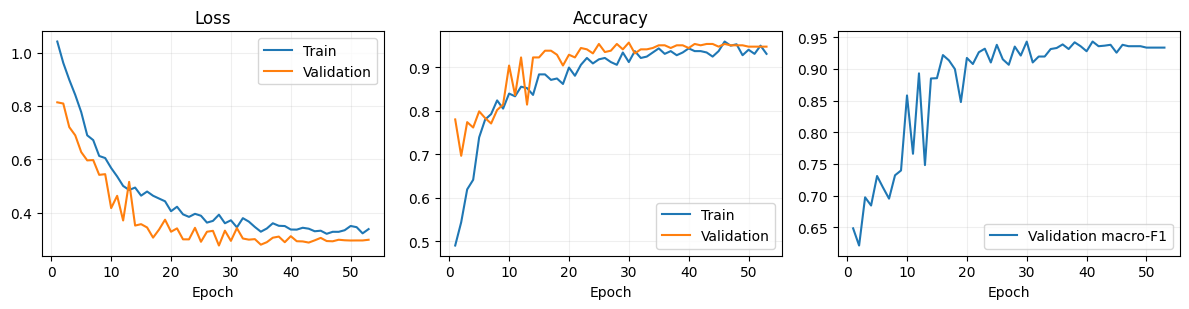

In [9]:
fig, axes = plt.subplots(1,3,figsize=(12,3.2))
for ax,key in zip(axes[:2],['loss','accuracy']):
    ax.plot(np.arange(1,len(history_df)+1), history_df[key], label='Train')
    ax.plot(np.arange(1,len(history_df)+1), history_df['val_'+key], label='Validation')
    ax.set_title(key.title()); ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=.2)
axes[2].plot(np.arange(1,len(history_df)+1),history_df.val_macro_f1,label='Validation macro-F1')
axes[2].set_xlabel('Epoch'); axes[2].legend(); axes[2].grid(alpha=.2)
fig.tight_layout(); save_figure(fig,'03_learning_curves.png'); plt.show(); plt.close(fig)

## 8. Final multiclass evaluation
Predict each split once with augmentation disabled. Argmax chooses one of three softmax probabilities; no binary threshold is used. Macro precision/recall/F1, balanced accuracy and Healthy recall matter more than accuracy alone. Training scores describe the selected balanced subset. ROC and average precision use one-vs-rest class probabilities.

In [10]:
split_inputs, predictions_by_split, confusion_matrices = {}, {}, {}
metric_rows, per_class_rows = [], []
for name, frame, ds in [('Train',df_train,train_eval_ds),('Validation',df_valid,valid_ds),('Test',df_test,test_ds)]:
    y = frame.label.to_numpy(dtype=int)
    prob = model.predict(ds, verbose=0)
    assert prob.shape == (len(frame), N_CLASSES)
    assert np.isfinite(prob).all() and np.allclose(prob.sum(axis=1),1,atol=1e-5)
    pred = prob.argmax(axis=1)
    split_inputs[name] = (y,prob)
    predictions_by_split[name] = pred
    cm = confusion_matrix(y,pred,labels=np.arange(N_CLASSES))
    confusion_matrices[name] = cm
    one_hot = np.eye(N_CLASSES)[y]
    metric_rows.append({'Dataset':name, 'Accuracy':accuracy_score(y,pred),
        'Balanced accuracy':balanced_accuracy_score(y,pred),
        'Precision':precision_score(y,pred,labels=np.arange(N_CLASSES),average='macro',zero_division=0),
        'Recall':recall_score(y,pred,labels=np.arange(N_CLASSES),average='macro',zero_division=0),
        'F1':f1_score(y,pred,labels=np.arange(N_CLASSES),average='macro',zero_division=0),
        'Weighted F1':f1_score(y,pred,average='weighted',zero_division=0),
        'ROC-AUC macro OVR':roc_auc_score(y,prob,labels=np.arange(N_CLASSES),multi_class='ovr',average='macro'),
        'Average precision macro':average_precision_score(one_hot,prob,average='macro')})
    report = classification_report(y,pred,labels=np.arange(N_CLASSES),target_names=CLASS_NAMES,output_dict=True,zero_division=0)
    print(name, '\n', classification_report(y,pred,labels=np.arange(N_CLASSES),target_names=CLASS_NAMES,digits=4,zero_division=0))
    (OUTPUT_DIR / f'{name.lower()}_classification_report.json').write_text(json.dumps(report,indent=2))
    for c, class_name in enumerate(CLASS_NAMES):
        tp=cm[c,c]; fn=cm[c,:].sum()-tp; fp=cm[:,c].sum()-tp; tn=cm.sum()-tp-fn-fp
        per_class_rows.append({'Dataset':name,'Class':class_name,**report[class_name],
            'Specificity':float(tn/(tn+fp)) if tn+fp else np.nan})
    out = frame.copy()
    out['predicted_label'] = pred
    out['predicted_class'] = [CLASS_NAMES[c] for c in pred]
    for c,class_name in enumerate(CLASS_NAMES):
        out[f'probability_{class_name}'] = prob[:,c]
    out.to_csv(OUTPUT_DIR / f'{name.lower()}_predictions.csv',index=False)
metrics_df = pd.DataFrame(metric_rows).set_index('Dataset')
classification_metrics_df = metrics_df[['Accuracy','Precision','Recall','F1']]
per_class_metrics_df = pd.DataFrame(per_class_rows)
display(metrics_df.round(4)); display(per_class_metrics_df.round(4))
metrics_df.to_csv(OUTPUT_DIR / 'all_metrics.csv')
classification_metrics_df.to_csv(OUTPUT_DIR / 'accuracy_precision_recall_f1_all_splits.csv')
per_class_metrics_df.to_csv(OUTPUT_DIR / 'per_class_metrics.csv',index=False)

Train 
               precision    recall  f1-score   support

Early_blight     0.9802    0.9340    0.9565       106
     Healthy     0.9714    0.9623    0.9668       106
 Late_blight     0.9018    0.9528    0.9266       106

    accuracy                         0.9497       318
   macro avg     0.9511    0.9497    0.9500       318
weighted avg     0.9511    0.9497    0.9500       318

Validation 
               precision    recall  f1-score   support

Early_blight     0.9929    0.9333    0.9622       150
     Healthy     0.8800    0.9565    0.9167        23
 Late_blight     0.9299    0.9733    0.9511       150

    accuracy                         0.9536       323
   macro avg     0.9343    0.9544    0.9433       323
weighted avg     0.9556    0.9536    0.9538       323

Test 
               precision    recall  f1-score   support

Early_blight     0.9932    0.9733    0.9832       150
     Healthy     0.8800    0.9565    0.9167        23
 Late_blight     0.9669    0.9733    0.9701    

,Accuracy,Balanced accuracy,Precision,Recall,F1,Weighted F1,ROC-AUC macro OVR,Average precision macro
Dataset,,,,,,,,
Train,0.9497,0.9497,0.9511,0.9497,0.9500,0.9500,0.9957,0.9921
Validation,0.9536,0.9544,0.9343,0.9544,0.9433,0.9538,0.9952,0.9883
Test,0.9721,0.9677,0.9467,0.9677,0.9566,0.9724,0.9977,0.9924


,Dataset,Class,precision,recall,f1-score,support,Specificity
0,Train,Early_blight,0.9802,0.9340,0.9565,106.0,0.9906
1,Train,Healthy,0.9714,0.9623,0.9668,106.0,0.9858
2,Train,Late_blight,0.9018,0.9528,0.9266,106.0,0.9481
3,Validation,Early_blight,0.9929,0.9333,0.9622,150.0,0.9942
4,Validation,Healthy,0.8800,0.9565,0.9167,23.0,0.9900
5,Validation,Late_blight,0.9299,0.9733,0.9511,150.0,0.9364
6,Test,Early_blight,0.9932,0.9733,0.9832,150.0,0.9942
7,Test,Healthy,0.8800,0.9565,0.9167,23.0,0.9900
8,Test,Late_blight,0.9669,0.9733,0.9701,150.0,0.9711


## 9. Confusion matrices and held-out class ROC/PR curves

Saved: /content/mydrive/MyDrive/Potato_ViT_Results_Balanced/figures/04_confusion_matrices.png


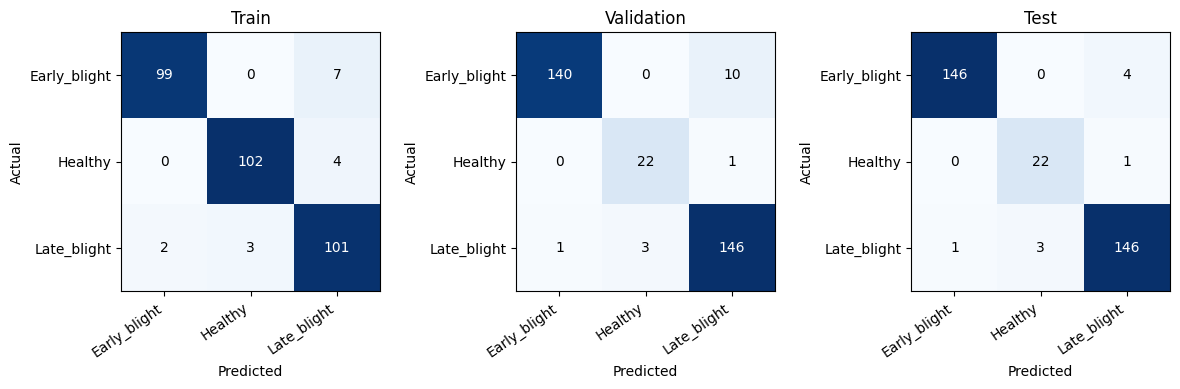

Saved: /content/mydrive/MyDrive/Potato_ViT_Results_Balanced/figures/05_test_roc_pr.png


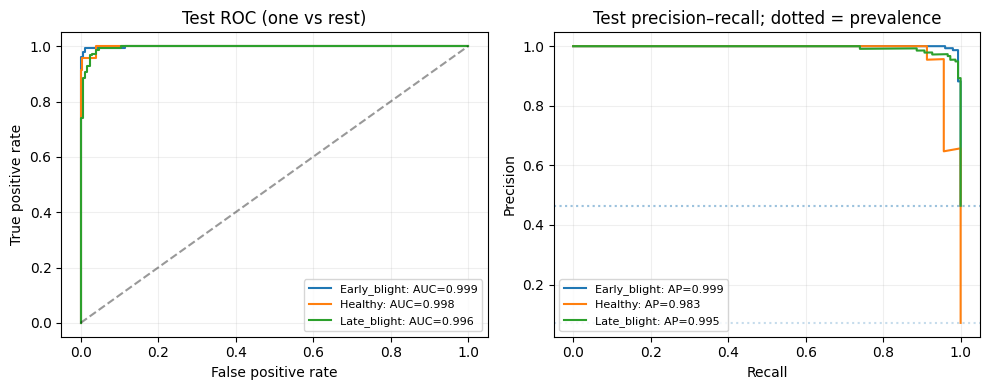

In [11]:
fig, axes = plt.subplots(1,3,figsize=(12,3.8))
for ax,(name,cm) in zip(axes,confusion_matrices.items()):
    ax.imshow(cm,cmap='Blues'); ax.set_title(name)
    ax.set_xticks(range(N_CLASSES),CLASS_NAMES,rotation=35,ha='right')
    ax.set_yticks(range(N_CLASSES),CLASS_NAMES)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            ax.text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>cm.max()/2 else 'black')
fig.tight_layout(); save_figure(fig,'04_confusion_matrices.png'); plt.show(); plt.close(fig)
y,prob = split_inputs['Test']
fig,axes = plt.subplots(1,2,figsize=(10,4))
for c,name in enumerate(CLASS_NAMES):
    binary = (y == c).astype(int)
    fpr,tpr,_ = roc_curve(binary,prob[:,c])
    precision,recall,_ = precision_recall_curve(binary,prob[:,c])
    axes[0].plot(fpr,tpr,label=f'{name}: AUC={roc_auc_score(binary,prob[:,c]):.3f}')
    axes[1].plot(recall,precision,label=f'{name}: AP={average_precision_score(binary,prob[:,c]):.3f}')
    axes[1].axhline(binary.mean(),linestyle=':',alpha=.25)
axes[0].plot([0,1],[0,1],'k--',alpha=.4)
axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='Test ROC (one vs rest)')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Test precision–recall; dotted = prevalence')
for ax in axes:ax.legend(fontsize=8);ax.grid(alpha=.2)
fig.tight_layout(); save_figure(fig,'05_test_roc_pr.png'); plt.show(); plt.close(fig)

## 10. Interpretation and next experiments
Check Healthy recall and macro-F1, not just overall accuracy. A large training–validation gap suggests overfitting; poor scores on both suggest underfitting or insufficient data. Undersampling alone cannot solve the shortage of independent Healthy images. Add genuinely new Healthy leaves and consider plant-level grouping. Keep the test set frozen after this evaluation; compare settings using validation only. No improved accuracy is claimed before running this notebook on the actual Drive images.

In [12]:
print('Balanced training count per class:', target_per_class)
print('Best checkpoint:', best_model_path)
print('Results:', OUTPUT_DIR)
print('Train minus validation macro-F1:', round(metrics_df.loc['Train','F1']-metrics_df.loc['Validation','F1'],4))
display(classification_metrics_df.round(4))

Balanced training count per class: 106
Best checkpoint: /content/mydrive/MyDrive/Potato_ViT_Results_Balanced/best_vit_potato.keras
Results: /content/mydrive/MyDrive/Potato_ViT_Results_Balanced
Train minus validation macro-F1: 0.0066


,Accuracy,Precision,Recall,F1
Dataset,,,,
Train,0.9497,0.9511,0.9497,0.9500
Validation,0.9536,0.9343,0.9544,0.9433
Test,0.9721,0.9467,0.9677,0.9566
